# 04 · Figures and tables for the paper
Means over 3 seeds. 95% CIs: galaxy-level bootstrap (1,000 resamples) of the per-galaxy mean over seeds.
Everything the paper quotes is written to `results/summary.json` and `results/tables/`.

In [1]:
import sys, warnings, json; from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT/'src')); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
from models import PRETTY, MODELS
plt.rcParams.update({'font.size': 8, 'figure.dpi': 120, 'savefig.bbox': 'tight', 'pdf.fonttype': 42})
FIG = ROOT/'results/figures'; TAB = ROOT/'results/tables'; FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
R = pd.read_csv(ROOT/'results/runs.csv'); X = pd.read_csv(ROOT/'results/xai_per_galaxy.csv'); C = pd.read_csv(ROOT/'results/xai_cost.csv')
CAMGRID = {'resnet50':'4×4','resnet18':'4×4','efficientnet_b0':'4×4','mobilenetv3_small_100':'4×4','vit_tiny_patch16_224':'8×8','small_cnn':'16×16'}
METH = {'gradcam':'Grad-CAM','gradcam++':'Grad-CAM++','scorecam':'Score-CAM'}
rng = np.random.default_rng(0)
def boot(v, n=1000):
    v = np.asarray(v, float); v = v[~np.isnan(v)]; b = rng.choice(v, (n, len(v))).mean(1)
    return float(v.mean()), float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5))
S = {}  # summary for the paper

In [2]:
# Table 1: accuracy and cost
g = R.groupby('model')
T1 = pd.DataFrame({'Params (M)': g.params.first()/1e6, 'GFLOPs': g.gflops.first(),
     'Acc': g.accuracy.mean(), 'Acc sd': g.accuracy.std(), 'AUC': g.roc_auc.mean(), 'AUC sd': g.roc_auc.std(),
     'Recall': g.recall.mean(), 'ECE': g.ece.mean(), 'Epochs': g.epochs.mean(),
     'Train (s)': g.train_seconds.mean(), 'Train (kJ)': g.train_joules.mean()/1e3, 'Train GPU (kJ)': g.train_gpu_joules.mean()/1e3,
     'Train CO2e (g)': g.train_kgco2e.mean()*1e3, 'Infer (J/1k)': g.inf_per1k_joules.mean()}).loc[MODELS]
S['table1'] = T1.round(5).to_dict(orient='index')
T1.rename(index=PRETTY).round(3)

,Params (M),GFLOPs,Acc,Acc sd,AUC,AUC sd,Recall,ECE,Epochs,Train (s),Train (kJ),Train GPU (kJ),Train CO2e (g),Infer (J/1k)
model,,,,,,,,,,,,,,
ResNet-50,23.506,2.618,0.912,0.020,0.966,0.006,0.908,0.038,17.000,111.137,2.584,1.957,0.144,31.263
ResNet-18,11.171,1.133,0.924,0.017,0.971,0.003,0.944,0.040,17.667,35.573,0.830,0.688,0.046,8.778
EfficientNet-B0,4.010,0.247,0.911,0.008,0.950,0.006,0.901,0.060,17.667,88.025,1.664,1.305,0.092,19.999
MobileNetV3-S,1.520,0.035,0.905,0.012,0.953,0.003,0.917,0.063,19.333,22.374,0.395,0.291,0.022,4.260
ViT-Tiny,5.401,0.696,0.919,0.003,0.961,0.011,0.937,0.037,16.667,30.069,0.724,0.565,0.040,7.461
SmallCNN,0.294,0.420,0.810,0.015,0.904,0.020,0.759,0.039,18.333,23.699,0.517,0.394,0.029,5.735


In [3]:
# Table 2: explanation fidelity vs physical ground truth (all methods)
rows = {}
for m in MODELS:
    for meth in METH:
        d = X[(X.model==m)&(X.method==meth)].groupby('key')[['TEF','TEL','GEF','PG','DEL','AGR']].mean()
        r = {k: boot(d[k]) for k in ['TEL','PG','DEL','AGR','TEF','GEF']}
        rows[(m, meth)] = r
S['table2'] = {f'{m}|{meth}': v for (m, meth), v in rows.items()}
T2 = pd.DataFrame({(PRETTY[m], METH[meth]): {k: f'{v[0]:.2f} [{v[1]:.2f},{v[2]:.2f}]' for k, v in r.items()} for (m, meth), r in rows.items()}).T
S['tail_area_mean'] = float(X.drop_duplicates('key').tail_area.mean())
S['n_test_jf'] = int(X.key.nunique())
T2

TEL                PG  \
ResNet-50       Grad-CAM    2.63 [2.47,2.78]  0.52 [0.45,0.59]   
                Grad-CAM++  2.95 [2.84,3.06]  0.60 [0.52,0.68]   
                Score-CAM   3.57 [3.45,3.69]  0.60 [0.52,0.67]   
ResNet-18       Grad-CAM    2.57 [2.46,2.66]  0.46 [0.39,0.53]   
                Grad-CAM++  2.70 [2.63,2.77]  0.50 [0.43,0.58]   
                Score-CAM   3.00 [2.92,3.09]  0.57 [0.50,0.64]   
EfficientNet-B0 Grad-CAM    1.07 [1.00,1.15]  0.12 [0.09,0.16]   
                Grad-CAM++  1.64 [1.44,1.84]  0.18 [0.13,0.23]   
                Score-CAM   2.38 [2.13,2.65]  0.24 [0.19,0.28]   
MobileNetV3-S   Grad-CAM    1.16 [1.07,1.26]  0.16 [0.13,0.20]   
                Grad-CAM++  1.41 [1.36,1.47]  0.15 [0.11,0.18]   
                Score-CAM   2.50 [2.36,2.64]  0.32 [0.27,0.38]   
ViT-Tiny        Grad-CAM    1.61 [1.53,1.70]  0.30 [0.26,0.34]   
                Grad-CAM++  1.78 [1.53,2.00]  0.15 [0.13,0.18]   
                Score-CAM   4.57 [4.21,4.98]  0.52 [0.45,0.58]   
SmallCNN        Grad-CAM    5.05 [4.58,5.52]  0.74 [0.70,0.78]   
                Grad-CAM++  5.06 [4.67,5.43]  0.75 [0.71,0.79]   
                Score-CAM   5.09 [4.67,5.48]  0.74 [0.70,0.78]   

                                         DEL               AGR  \
ResNet-50       Grad-CAM    0.53 [0.50,0.56]  1.00 [1.00,1.00]   
                Grad-CAM++  0.50 [0.47,0.53]  1.00 [1.00,1.00]   
                Score-CAM   0.41 [0.38,0.44]  1.00 [1.00,1.00]   
ResNet-18       Grad-CAM    0.61 [0.59,0.63]  0.56 [0.52,0.60]   
                Grad-CAM++  0.59 [0.57,0.61]  0.69 [0.66,0.71]   
                Score-CAM   0.57 [0.55,0.60]  0.84 [0.83,0.86]   
EfficientNet-B0 Grad-CAM    0.67 [0.63,0.70]  0.13 [0.09,0.16]   
                Grad-CAM++  0.56 [0.53,0.60]  0.28 [0.24,0.32]   
                Score-CAM   0.53 [0.49,0.56]  0.49 [0.45,0.53]   
MobileNetV3-S   Grad-CAM    0.63 [0.60,0.66]  0.17 [0.15,0.20]   
                Grad-CAM++  0.66 [0.63,0.68]  0.21 [0.18,0.25]   
                Score-CAM   0.47 [0.45,0.49]  0.47 [0.43,0.50]   
ViT-Tiny        Grad-CAM    0.60 [0.57,0.63]  0.09 [0.07,0.11]   
                Grad-CAM++  0.70 [0.67,0.73]  0.24 [0.20,0.28]   
                Score-CAM   0.34 [0.31,0.36]  0.35 [0.31,0.38]   
SmallCNN        Grad-CAM    0.31 [0.28,0.34]  0.25 [0.22,0.27]   
                Grad-CAM++  0.43 [0.41,0.45]  0.45 [0.43,0.46]   
                Score-CAM   0.48 [0.46,0.50]  0.69 [0.68,0.70]   

                                         TEF               GEF  
ResNet-50       Grad-CAM    0.21 [0.18,0.23]  0.23 [0.20,0.26]  
                Grad-CAM++  0.22 [0.20,0.25]  0.25 [0.22,0.28]  
                Score-CAM   0.26 [0.23,0.29]  0.29 [0.26,0.32]  
ResNet-18       Grad-CAM    0.20 [0.18,0.23]  0.23 [0.20,0.25]  
                Grad-CAM++  0.21 [0.18,0.24]  0.23 [0.21,0.26]  
                Score-CAM   0.23 [0.20,0.26]  0.25 [0.23,0.28]  
EfficientNet-B0 Grad-CAM    0.10 [0.09,0.12]  0.11 [0.09,0.13]  
                Grad-CAM++  0.16 [0.14,0.19]  0.17 [0.14,0.20]  
                Score-CAM   0.17 [0.14,0.19]  0.19 [0.16,0.21]  
MobileNetV3-S   Grad-CAM    0.11 [0.09,0.13]  0.13 [0.11,0.15]  
                Grad-CAM++  0.11 [0.09,0.12]  0.13 [0.11,0.14]  
                Score-CAM   0.19 [0.16,0.21]  0.21 [0.19,0.24]  
ViT-Tiny        Grad-CAM    0.12 [0.10,0.13]  0.13 [0.12,0.14]  
                Grad-CAM++  0.12 [0.11,0.14]  0.13 [0.12,0.15]  
                Score-CAM   0.29 [0.26,0.31]  0.37 [0.34,0.40]  
SmallCNN        Grad-CAM    0.29 [0.26,0.31]  0.32 [0.29,0.34]  
                Grad-CAM++  0.29 [0.27,0.32]  0.33 [0.31,0.35]  
                Score-CAM   0.29 [0.27,0.31]  0.33 [0.31,0.36]

In [4]:
# Table 3: energy of explanations
P = C.pivot(index='model', columns='method', values='xai_per1k_joules').loc[MODELS]
Pt = C.pivot(index='model', columns='method', values='xai_per1k_seconds').loc[MODELS]
T3 = pd.DataFrame({'Grad-CAM (J/1k)': P['gradcam'], 'Grad-CAM++ (J/1k)': P['gradcam++'], 'Score-CAM (J/1k)': P['scorecam'],
                   'Score/Grad': P['scorecam']/P['gradcam'], 'Infer (J/1k)': T1['Infer (J/1k)'],
                   'Score-CAM 1k / training': P['scorecam']/(T1['Train (kJ)']*1e3), 'Score-CAM (s/1k)': Pt['scorecam']})
S['table3'] = T3.round(5).to_dict(orient='index')
T3.rename(index=PRETTY).round(2)

,Grad-CAM (J/1k),Grad-CAM++ (J/1k),Score-CAM (J/1k),Score/Grad,Infer (J/1k),Score-CAM 1k / training,Score-CAM (s/1k)
model,,,,,,,
ResNet-50,142.54,145.72,66370.51,465.63,31.26,25.68,3263.03
ResNet-18,57.73,62.64,6175.86,106.98,8.78,7.44,336.19
EfficientNet-B0,94.58,95.01,27449.59,290.22,20.00,16.49,1514.10
MobileNetV3-S,24.05,26.44,3314.51,137.83,4.26,8.40,311.61
ViT-Tiny,25.53,26.47,1408.99,55.18,7.46,1.95,132.41
SmallCNN,55.51,56.20,941.56,16.96,5.73,1.82,62.14


In [5]:
# LaTeX tables (compact, for the paper)
PM, TIMES, NL = r'$\pm$', r'$\times$', r' \\'
L1 = [r'\begin{tabular}{lrrcccrrr}', r'\toprule',
      r'Model & Params & GFLOPs & Accuracy & ROC-AUC & ECE & Train (s) & Train (kJ) & Infer. (J/1k) \\', r'\midrule']
for m in MODELS:
    r = T1.loc[m]
    L1.append(' & '.join([PRETTY[m], '%.2fM' % r['Params (M)'], '%.3f' % r['GFLOPs'],
                          '%.3f%s%.3f' % (r['Acc'], PM, r['Acc sd']), '%.3f%s%.3f' % (r['AUC'], PM, r['AUC sd']),
                          '%.3f' % r['ECE'], '%.0f' % r['Train (s)'], '%.2f' % r['Train (kJ)'], '%.1f' % r['Infer (J/1k)']]) + NL)
L1 += [r'\bottomrule', r'\end{tabular}']
(TAB/'table1.tex').write_text('\n'.join(L1))

L2 = [r'\begin{tabular}{lcccccccc}', r'\toprule',
      r' & CAM & \multicolumn{3}{c}{Tail lift (TEL) $\uparrow$} & \multicolumn{3}{c}{Gas pointing (PG) $\uparrow$} & Agree. \\',
      r'\cmidrule(lr){3-5}\cmidrule(lr){6-8}',
      r'Model & grid & GC & GC++ & SC & GC & GC++ & SC & GC \\', r'\midrule']
for m in MODELS:
    t = ['%.2f' % rows[(m, k)]['TEL'][0] for k in METH]; pg = ['%.2f' % rows[(m, k)]['PG'][0] for k in METH]
    L2.append(' & '.join([PRETTY[m], CAMGRID[m].replace('×', TIMES)] + t + pg + ['%.2f' % rows[(m, 'gradcam')]['AGR'][0]]) + NL)
L2 += [r'\bottomrule', r'\end{tabular}']
(TAB/'table2.tex').write_text('\n'.join(L2))

L3 = [r'\begin{tabular}{lrrrrr}', r'\toprule', r'Model & Inference & Grad-CAM & Score-CAM & SC/GC & SC (1k) / training \\', r'\midrule']
for m in MODELS:
    r = T3.loc[m]
    L3.append(' & '.join([PRETTY[m], '%.1f' % r['Infer (J/1k)'], '%.1f' % r['Grad-CAM (J/1k)'],
                          '{:,.0f}'.format(r['Score-CAM (J/1k)']).replace(',', '{,}'),
                          '%.0f%s' % (r['Score/Grad'], TIMES), '%.2f%s' % (r['Score-CAM 1k / training'], TIMES)]) + NL)
L3 += [r'\bottomrule', r'\end{tabular}']
(TAB/'table3.tex').write_text('\n'.join(L3))
print((TAB/'table2.tex').read_text())

\begin{tabular}{lcccccccc}
\toprule
 & CAM & \multicolumn{3}{c}{Tail lift (TEL) $\uparrow$} & \multicolumn{3}{c}{Gas pointing (PG) $\uparrow$} & Agree. \\
\cmidrule(lr){3-5}\cmidrule(lr){6-8}
Model & grid & GC & GC++ & SC & GC & GC++ & SC & GC \\
\midrule
ResNet-50 & 4$\times$4 & 2.63 & 2.95 & 3.57 & 0.52 & 0.60 & 0.60 & 1.00 \\
ResNet-18 & 4$\times$4 & 2.57 & 2.70 & 3.00 & 0.46 & 0.50 & 0.57 & 0.56 \\
EfficientNet-B0 & 4$\times$4 & 1.07 & 1.64 & 2.38 & 0.12 & 0.18 & 0.24 & 0.13 \\
MobileNetV3-S & 4$\times$4 & 1.16 & 1.41 & 2.50 & 0.16 & 0.15 & 0.32 & 0.17 \\
ViT-Tiny & 8$\times$8 & 1.61 & 1.78 & 4.57 & 0.30 & 0.15 & 0.52 & 0.09 \\
SmallCNN & 16$\times$16 & 5.05 & 5.06 & 5.09 & 0.74 & 0.75 & 0.74 & 0.25 \\
\bottomrule
\end{tabular}


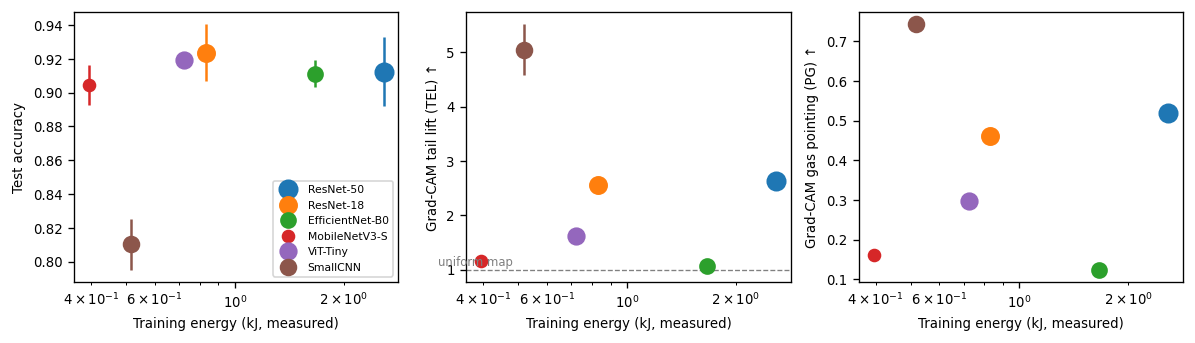

In [6]:
# Figure: accuracy and explanation fidelity vs training energy
s = T1[['Acc','Acc sd','Train (kJ)','GFLOPs']].copy()
s['TEL'] = [rows[(m,'gradcam')]['TEL'][0] for m in s.index]; s['TELlo'] = [rows[(m,'gradcam')]['TEL'][1] for m in s.index]; s['TELhi'] = [rows[(m,'gradcam')]['TEL'][2] for m in s.index]
s['PG'] = [rows[(m,'gradcam')]['PG'][0] for m in s.index]
fig, ax = plt.subplots(1, 3, figsize=(10, 2.9))
cols = dict(zip(MODELS, plt.cm.tab10.colors))
for m, r in s.iterrows():
    sz = 25 + 40*np.log10(1 + 100*r.GFLOPs)
    ax[0].errorbar(r['Train (kJ)'], r.Acc, r['Acc sd'], fmt='o', ms=np.sqrt(sz), c=cols[m], label=PRETTY[m])
    ax[1].errorbar(r['Train (kJ)'], r.TEL, [[r.TEL-r.TELlo], [r.TELhi-r.TEL]], fmt='o', ms=np.sqrt(sz), c=cols[m])
    ax[2].scatter(r['Train (kJ)'], r.PG, s=sz, c=[cols[m]])
ax[1].axhline(1, ls='--', c='gray', lw=0.8); ax[1].text(ax[1].get_xlim()[0]*1.05, 1.08, 'uniform map', fontsize=7, color='gray')
for a, l in zip(ax, ['Test accuracy', 'Grad-CAM tail lift (TEL) ↑', 'Grad-CAM gas pointing (PG) ↑']):
    a.set_xscale('log'); a.set_xlabel('Training energy (kJ, measured)'); a.set_ylabel(l)
ax[0].legend(fontsize=6.5, loc='lower right')
plt.tight_layout(); plt.savefig(FIG/'fig_pareto.pdf')

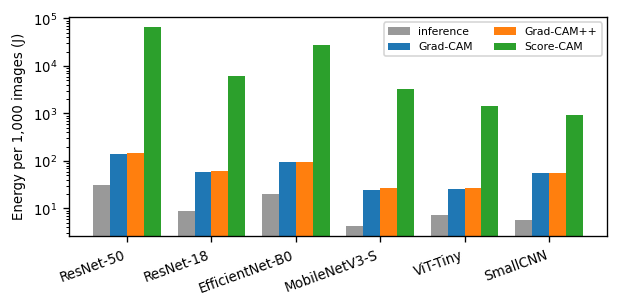

In [7]:
# Figure: energy per 1,000 explanations vs inference
fig, ax = plt.subplots(figsize=(5.2, 2.6))
w = 0.2; xs = np.arange(len(MODELS))
ax.bar(xs-1.5*w, T1['Infer (J/1k)'], w, label='inference', color='0.6')
for k, (meth, lab) in enumerate(METH.items()):
    ax.bar(xs+(k-0.5)*w, P[meth], w, label=lab)
ax.set_yscale('log'); ax.set_xticks(xs); ax.set_xticklabels([PRETTY[m] for m in MODELS], rotation=20, ha='right')
ax.set_ylabel('Energy per 1,000 images (J)'); ax.legend(fontsize=6.5, ncol=2)
plt.tight_layout(); plt.savefig(FIG/'fig_xai_cost.pdf')

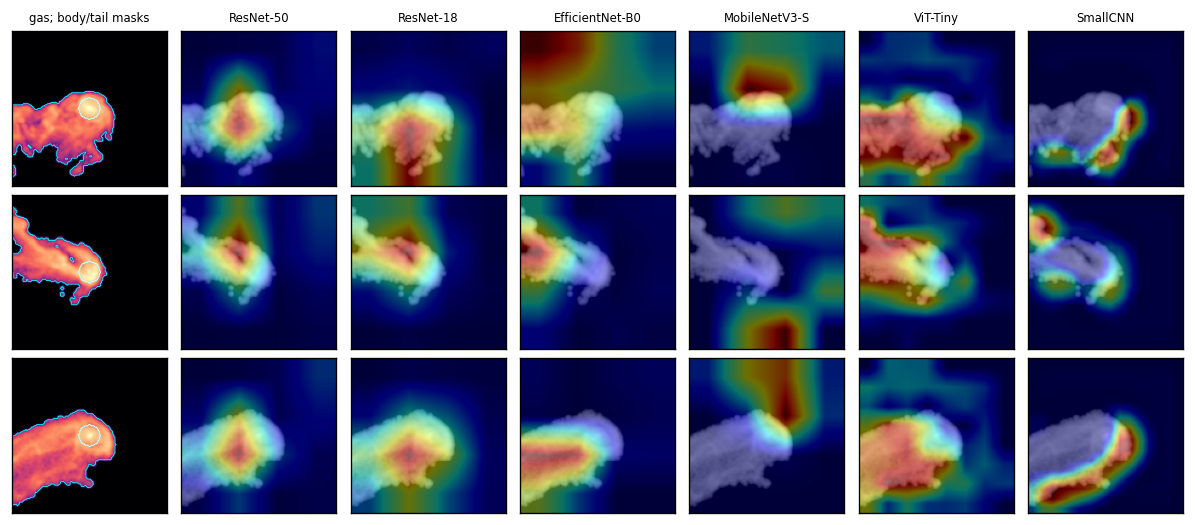

In [8]:
# Figure: same galaxies, all models (Grad-CAM, seed 0)
from data import load_maps, to_image, physical_masks
cams = np.load(ROOT/'results/cams_seed0.npy', allow_pickle=True).item()
df = pd.read_csv(ROOT/'data/processed/splits.csv'); te = df[(df.split=='test')&(df.label==1)].reset_index(drop=True)
x0 = X[(X.method=='gradcam')&(X.seed==0)&(X.model=='resnet50')].set_index('key').loc[te.key]
pick = x0.reset_index().query('tail_area > 0.06').sort_values('p_jf', ascending=False).index[:3]
fig, ax = plt.subplots(3, len(MODELS)+1, figsize=(10, 4.4))
for i, k in enumerate(pick):
    r = te.iloc[k]; gimg = to_image(load_maps(r.key)[0]); body, _, tail = physical_masks(r)
    ax[i,0].imshow(gimg, cmap='magma', origin='lower'); ax[i,0].contour(tail, [0.5], colors='cyan', linewidths=0.5); ax[i,0].contour(body, [0.5], colors='white', linewidths=0.5)
    for j, m in enumerate(MODELS):
        ax[i,j+1].imshow(gimg, cmap='gray', origin='lower'); ax[i,j+1].imshow(cams[(m,'gradcam',0)][k].astype(float), cmap='jet', alpha=0.45, origin='lower', vmin=0, vmax=1)
        if i == 0: ax[i,j+1].set_title(PRETTY[m], fontsize=7)
ax[0,0].set_title('gas; body/tail masks', fontsize=7)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(FIG/'fig_cams.pdf', dpi=200)

In [9]:
S['dataset'] = {'n': int(len(df)), 'split': df.groupby('split').size().to_dict(), 'galaxies': int(df.branch.nunique())}
(ROOT/'results/summary.json').write_text(json.dumps(S, indent=1, default=float)); print('saved summary.json')

saved summary.json
